# NB07b — 1D-CNN Penultimate Embedding Extraction + Few-Shot Split

**Why this supersedes NB07 mean-pool (HANDOFF update 9):**  
Mean-pooling the (300, 384) MiniLM sequence discards temporal evolution — the UMAP showed legit-encryption bleeding into ransomware and variants scattering. The 1D-CNN's penultimate layer (64-d global-mean-pool of conv features) already encoded the temporal pattern to achieve 0.96 F1. Using that vector as the shared GAN/MAML representation preserves the temporal signal at tractable size.

**Penultimate layer:** after two Conv1d blocks (384→128→64 channels), global mean pool over 300 time steps → **(batch, 64)** — the vector just before the 3-way classification head.

**Outputs:**
- `features/cnn_penultimate.npy` — (190, 64) float32, all executions
- `features/classifier.pt` — trained model weights
- `features/fewshot_split_cnn.npz` — episodic split rebuilt on 64-d space
- `features/cnn_penultimate_umap.png` — UMAP vs mean-pool comparison

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
import umap
from pathlib import Path

FEATURES_DIR = Path('features')
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

LABEL_3WAY = {
    'WannaCry':'Ransomware','Ryuk':'Ransomware','REvil':'Ransomware',
    'LockBit':'Ransomware','Darkside':'Ransomware','Conti':'Ransomware',
    'AESCrypt':'Legit-Encryption','SDelete':'Legit-Encryption','Zip':'Legit-Encryption',
    'Firefox':'Benign','Office':'Benign','Idle':'Benign',
}
VARIANT_CLASSES = [f'Conti_0{i}' for i in range(1, 8)]
CLASS_ORDER = ['Benign', 'Legit-Encryption', 'Ransomware']  # matches NB05 encoding
print(f'Device: {device}')


/home/arshad/Claude/Projects/Directed Study/Ransomware/ransmap_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


## 1. Load embeddings + metadata

In [2]:
meta_df   = pd.read_csv(FEATURES_DIR / 'metadata.csv')
text_seqs = np.load(FEATURES_DIR / 'text_sequences.npy')  # (190, 300, 384)
labels    = meta_df['label'].values
groups    = meta_df['group'].values

labels_3way = np.array([LABEL_3WAY.get(l, l) for l in labels])
orig_mask   = groups == 'original'
var_mask    = groups == 'variant'

# Encode 3-way labels for training (originals only)
le = LabelEncoder()
le.fit(CLASS_ORDER)
y_orig = le.transform(labels_3way[orig_mask])  # (120,)

print(f'text_seqs : {text_seqs.shape}')
print(f'Originals : {orig_mask.sum()}  |  Variants : {var_mask.sum()}')
print(f'Classes   : {dict(zip(le.classes_, range(len(le.classes_))))}')


text_seqs : (190, 300, 384)
Originals : 120  |  Variants : 70
Classes   : {np.str_('Benign'): 0, np.str_('Legit-Encryption'): 1, np.str_('Ransomware'): 2}


## 2. 1D-CNN model (same architecture as NB05)

Penultimate vector = `features.mean(dim=-1)` — the 64-d output after both Conv1d blocks, before the linear classification head.

In [3]:
class TextEmbeddingClassifier(nn.Module):
    def __init__(self, seq_len=300, emb_dim=384, n_classes=3):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(emb_dim, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128), nn.ReLU(),
            nn.Conv1d(128, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),  nn.ReLU(),
        )
        self.classifier = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(32, n_classes),
        )
        self.reconstructor = nn.Sequential(
            nn.Linear(64, 128), nn.ReLU(),
            nn.Linear(128, emb_dim),
        )

    def forward(self, x):
        # x: (batch, 300, 384)
        x_t      = x.permute(0, 2, 1)          # (batch, 384, 300)
        features = self.conv(x_t)               # (batch, 64, 300)
        pooled   = features.mean(dim=-1)        # (batch, 64) ← PENULTIMATE
        logits   = self.classifier(pooled)
        recon    = self.reconstructor(pooled)
        return logits, recon, pooled

clf_model = TextEmbeddingClassifier().to(device)
total_params = sum(p.numel() for p in clf_model.parameters())
print(f'Parameters: {total_params:,}')
print(f'Penultimate dim: 64')


Parameters: 347,331
Penultimate dim: 64


In [4]:
class SeqDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

# 80/20 stratified split of 120 originals for training
orig_seqs = text_seqs[orig_mask]   # (120, 300, 384)
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, val_idx = next(sss.split(orig_seqs, y_orig))

train_ds  = SeqDataset(orig_seqs[tr_idx],  y_orig[tr_idx])
val_ds    = SeqDataset(orig_seqs[val_idx], y_orig[val_idx])
train_dl  = DataLoader(train_ds, batch_size=16, shuffle=True)
val_dl    = DataLoader(val_ds,   batch_size=16, shuffle=False)
print(f'Train: {len(train_ds)}  Val: {len(val_ds)}')


Train: 96  Val: 24


## 3. Train classifier (80 epochs)

In [5]:
EPOCHS    = 80
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(clf_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=25, gamma=0.5)

print(f"{'Epoch':>6}  {'Train Loss':>11}  {'Val Loss':>10}  {'Val Acc':>9}")
print('-' * 45)

for epoch in range(1, EPOCHS + 1):
    clf_model.train()
    tr_loss = 0.0
    for bx, by in train_dl:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        logits, _, _ = clf_model(bx)
        loss = criterion(logits, by)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item()

    clf_model.eval()
    vl_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for bx, by in val_dl:
            bx, by = bx.to(device), by.to(device)
            logits, _, _ = clf_model(bx)
            vl_loss += criterion(logits, by).item()
            correct += (logits.argmax(1) == by).sum().item()
            total   += len(by)
    scheduler.step()
    if epoch % 10 == 0 or epoch == 1:
        print(f'{epoch:>6}  {tr_loss/len(train_dl):>11.4f}  {vl_loss/len(val_dl):>10.4f}  {correct/total:>9.3f}')

# Save weights
torch.save(clf_model.state_dict(), FEATURES_DIR / 'classifier.pt')
print(f'\n✅ Model saved → features/classifier.pt')


 Epoch   Train Loss    Val Loss    Val Acc
---------------------------------------------
     1       0.9802      1.0782      0.500
    10       0.5661      0.6920      0.792
    20       0.2559      0.7291      0.750
    30       0.0878      0.2427      0.958
    40       0.0868      0.1835      1.000
    50       0.0357      0.2433      0.958
    60       0.0399      0.1917      0.958
    70       0.0454      0.3183      0.875
    80       0.0440      0.1499      0.958

✅ Model saved → features/classifier.pt


## 4. Extract 64-d penultimate embeddings (all 190 executions)

Freeze the trained CNN and run all 190 executions through it — originals AND variants. The variants were never in training, so their penultimate activations are a zero-day test of how the CNN's learned representation generalises.

In [6]:
clf_model.eval()
all_ds = SeqDataset(text_seqs, np.zeros(len(text_seqs), dtype=int))  # dummy labels
all_dl = DataLoader(all_ds, batch_size=16, shuffle=False)

penultimate_vecs = []
with torch.no_grad():
    for bx, _ in all_dl:
        bx = bx.to(device)
        x_t      = bx.permute(0, 2, 1)       # (batch, 384, 300)
        features = clf_model.conv(x_t)        # (batch, 64, 300)
        pooled   = features.mean(dim=-1)      # (batch, 64)
        penultimate_vecs.append(pooled.cpu().numpy())

cnn_penu = np.concatenate(penultimate_vecs, axis=0).astype(np.float32)  # (190, 64)
np.save(FEATURES_DIR / 'cnn_penultimate.npy', cnn_penu)

print(f'Penultimate embeddings shape : {cnn_penu.shape}')
print(f'L2 norm mean (originals)     : {np.linalg.norm(cnn_penu[orig_mask], axis=-1).mean():.3f}')
print(f'L2 norm mean (variants)      : {np.linalg.norm(cnn_penu[var_mask],  axis=-1).mean():.3f}')
print(f'Saved → features/cnn_penultimate.npy')


Penultimate embeddings shape : (190, 64)
L2 norm mean (originals)     : 4.522
L2 norm mean (variants)      : 4.248
Saved → features/cnn_penultimate.npy


## 5. UMAP comparison — mean-pool (384-d) vs CNN penultimate (64-d)

Side-by-side: if the CNN penultimate space shows tighter class clusters and variants closer to Conti (not scattered), it confirms the temporal encoding is worth preserving.

/home/arshad/Claude/Projects/Directed Study/Ransomware/ransmap_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


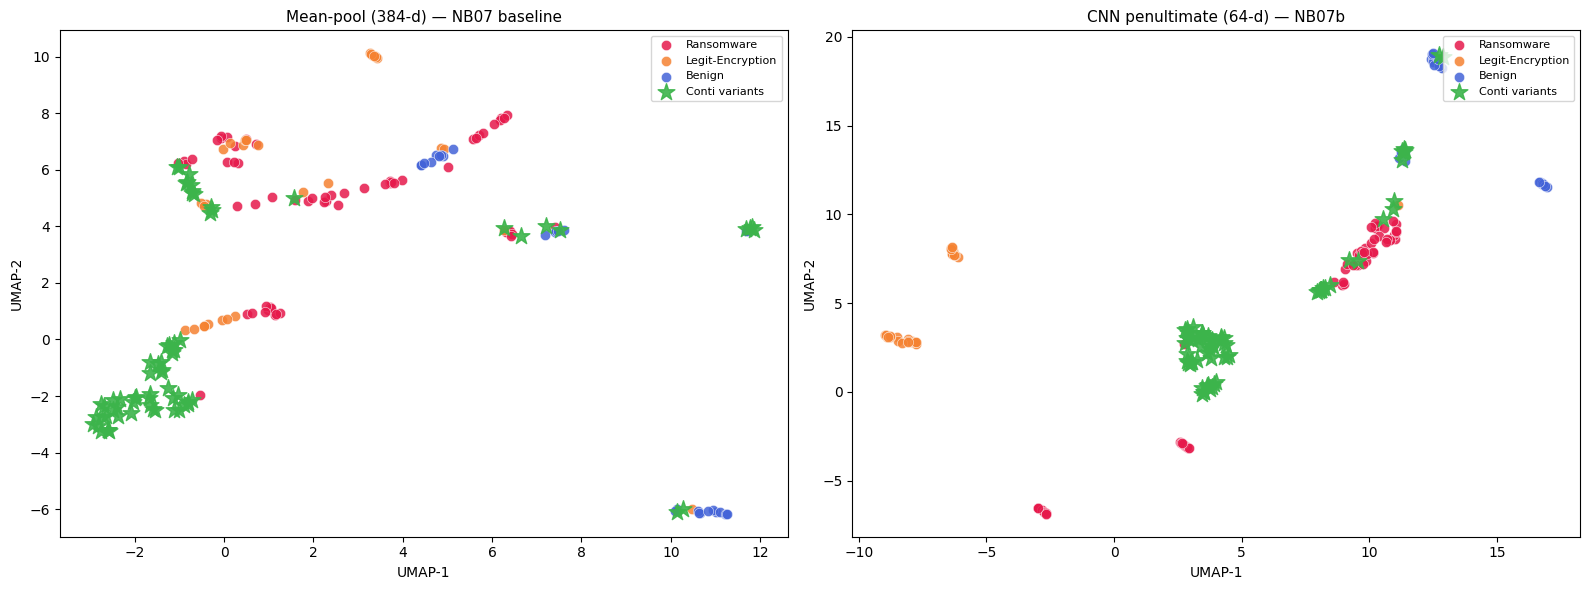

Saved → features/cnn_penultimate_umap.png


In [7]:
pooled_mean = np.load(FEATURES_DIR / 'pooled_embeddings.npy')   # (190, 384) from NB07

COLOR  = {'Ransomware':'#e6194b','Legit-Encryption':'#f58231','Benign':'#4363d8'}
VCOLOR = '#3cb44b'

reducer = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.1,
                    metric='cosine', random_state=SEED)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, vecs, title in [
    (axes[0], pooled_mean, 'Mean-pool (384-d) — NB07 baseline'),
    (axes[1], cnn_penu,   'CNN penultimate (64-d) — NB07b'),
]:
    emb = reducer.fit_transform(vecs)
    for cls in ['Ransomware', 'Legit-Encryption', 'Benign']:
        m = (labels_3way == cls) & orig_mask
        ax.scatter(emb[m,0], emb[m,1], c=COLOR[cls], label=cls, s=55, alpha=0.85,
                   edgecolors='white', linewidths=0.4)
    vm = var_mask
    ax.scatter(emb[vm,0], emb[vm,1], c=VCOLOR, marker='*', s=160,
               label='Conti variants', alpha=0.9)
    ax.set_title(title, fontsize=11)
    ax.legend(fontsize=8, loc='best')
    ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')

plt.tight_layout()
plt.savefig(FEATURES_DIR / 'cnn_penultimate_umap.png', dpi=150)
plt.show()
print('Saved → features/cnn_penultimate_umap.png')


## 6. Rebuild few-shot split on CNN penultimate space

Same 80/20 stratified split as NB07, now indexed into the 64-d penultimate embeddings.

In [8]:
orig_idx  = np.where(orig_mask)[0]
orig_3way = labels_3way[orig_mask]

sss2 = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_loc, val_loc = next(sss2.split(orig_idx, orig_3way))

train_idx_cnn = orig_idx[tr_loc]
val_idx_cnn   = orig_idx[val_loc]
test_idx_cnn  = np.where(var_mask)[0]

np.savez(
    FEATURES_DIR / 'fewshot_split_cnn.npz',
    train_idx      = train_idx_cnn,
    val_idx        = val_idx_cnn,
    test_idx       = test_idx_cnn,
    labels_3way    = labels_3way,
    labels_fine    = labels,
    class_names_3way = np.array(['Ransomware', 'Legit-Encryption', 'Benign']),
    variant_names  = np.array(VARIANT_CLASSES),
)

print('Few-shot split (CNN penultimate):')
print(f'  Train : {len(train_idx_cnn)} executions')
for cls in CLASS_ORDER:
    print(f'    {cls}: {(labels_3way[train_idx_cnn]==cls).sum()}')
print(f'  Val   : {len(val_idx_cnn)} executions')
print(f'  Test  : {len(test_idx_cnn)} executions (Conti variants)')
print('Saved → features/fewshot_split_cnn.npz')


Few-shot split (CNN penultimate):
  Train : 96 executions
    Benign: 24
    Legit-Encryption: 24
    Ransomware: 48
  Val   : 24 executions
  Test  : 70 executions (Conti variants)
Saved → features/fewshot_split_cnn.npz


## 7. Partner usage

```python
import numpy as np

# Load 64-d per-execution embeddings
X = np.load('features/cnn_penultimate.npy')       # (190, 64)

split = np.load('features/fewshot_split_cnn.npz', allow_pickle=True)
train_idx    = split['train_idx']     # 96 originals — sample episodes here
val_idx      = split['val_idx']       # 24 originals — validation episodes
test_idx     = split['test_idx']      # 70 Conti variants — zero-day test
labels_3way  = split['labels_3way']   # 'Ransomware' / 'Legit-Encryption' / 'Benign'
labels_fine  = split['labels_fine']   # 'WannaCry', 'AESCrypt', etc.

X_train = X[train_idx]   # (96, 64)
X_test  = X[test_idx]    # (70, 64)
```

**GAN note:** the GAN (NB08, Alliance) will generate new 64-d vectors matching the `X_train` distribution, emphasising Legit-Encryption. Generated vectors are appended to `X_train` before MAML episodic training.

In [9]:
print('=' * 58)
print('NB07b — CNN PENULTIMATE EXTRACTION + FEW-SHOT SPLIT')
print('=' * 58)
print(f'Source             : text_sequences.npy   {text_seqs.shape}')
print(f'CNN penultimate    : cnn_penultimate.npy  {cnn_penu.shape}  (64-d)')
print(f'Model weights      : classifier.pt')
print(f'Few-shot split     : fewshot_split_cnn.npz')
print(f'UMAP comparison    : cnn_penultimate_umap.png')
print()
print('Penultimate L2 norms:')
print(f'  Originals : {np.linalg.norm(cnn_penu[orig_mask], axis=-1).mean():.3f}')
print(f'  Variants  : {np.linalg.norm(cnn_penu[var_mask],  axis=-1).mean():.3f}')
print()
print('Next: GAN (NB08, Canada Alliance) — conditional GAN over 3 macro-classes,')
print('      generating 64-d CNN-penultimate vectors; emphasis on Legit-Encryption.')


NB07b — CNN PENULTIMATE EXTRACTION + FEW-SHOT SPLIT
Source             : text_sequences.npy   (190, 300, 384)
CNN penultimate    : cnn_penultimate.npy  (190, 64)  (64-d)
Model weights      : classifier.pt
Few-shot split     : fewshot_split_cnn.npz
UMAP comparison    : cnn_penultimate_umap.png

Penultimate L2 norms:
  Originals : 4.522
  Variants  : 4.248

Next: GAN (NB08, Canada Alliance) — conditional GAN over 3 macro-classes,
      generating 64-d CNN-penultimate vectors; emphasis on Legit-Encryption.
